# Pledge packet: detect barcode -> decode -> OCR -> compare (v3)
Put this notebook in the **same folder as `barcode_pipeline.py`**.

**What changed (OCR):** the printed number is no longer read as one line of text (Tesseract drops the thin digit `1`). The digit line is now cut into single digits, so the digit *count* is always right, and every digit is read by a template matcher with Tesseract as a second opinion. The OCR never looks at the decoded barcode value, so MATCHED still means two independent readings agree.

In [1]:
# run once, then skip
%pip install opencv-python numpy pyzbar pytesseract pillow pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, cv2, glob
import pandas as pd
from IPython.display import display, Image as IPImage
sys.path.insert(0, os.getcwd())
import importlib, barcode_pipeline as B
importlib.reload(B)                      # picks up edits to barcode_pipeline.py without restarting the kernel
print("pipeline loaded from:", B.__file__)

pipeline loaded from: c:\Users\Harisubramanian\Downloads\barcode_project_v3\barcode_project_v3\barcode_pipeline.py


## Section A: test ONE image

Decoded barcode : 41233285 (CODE128)
OCR number      : 41233285
Result          : BARCODE MATCHED
OCR detail      : {'n': 8, 'templates': '41233285', 'tesseract': None, 'dist_max': 13.0, 'agree': False, 'confident': True, 'method': 'digits'}


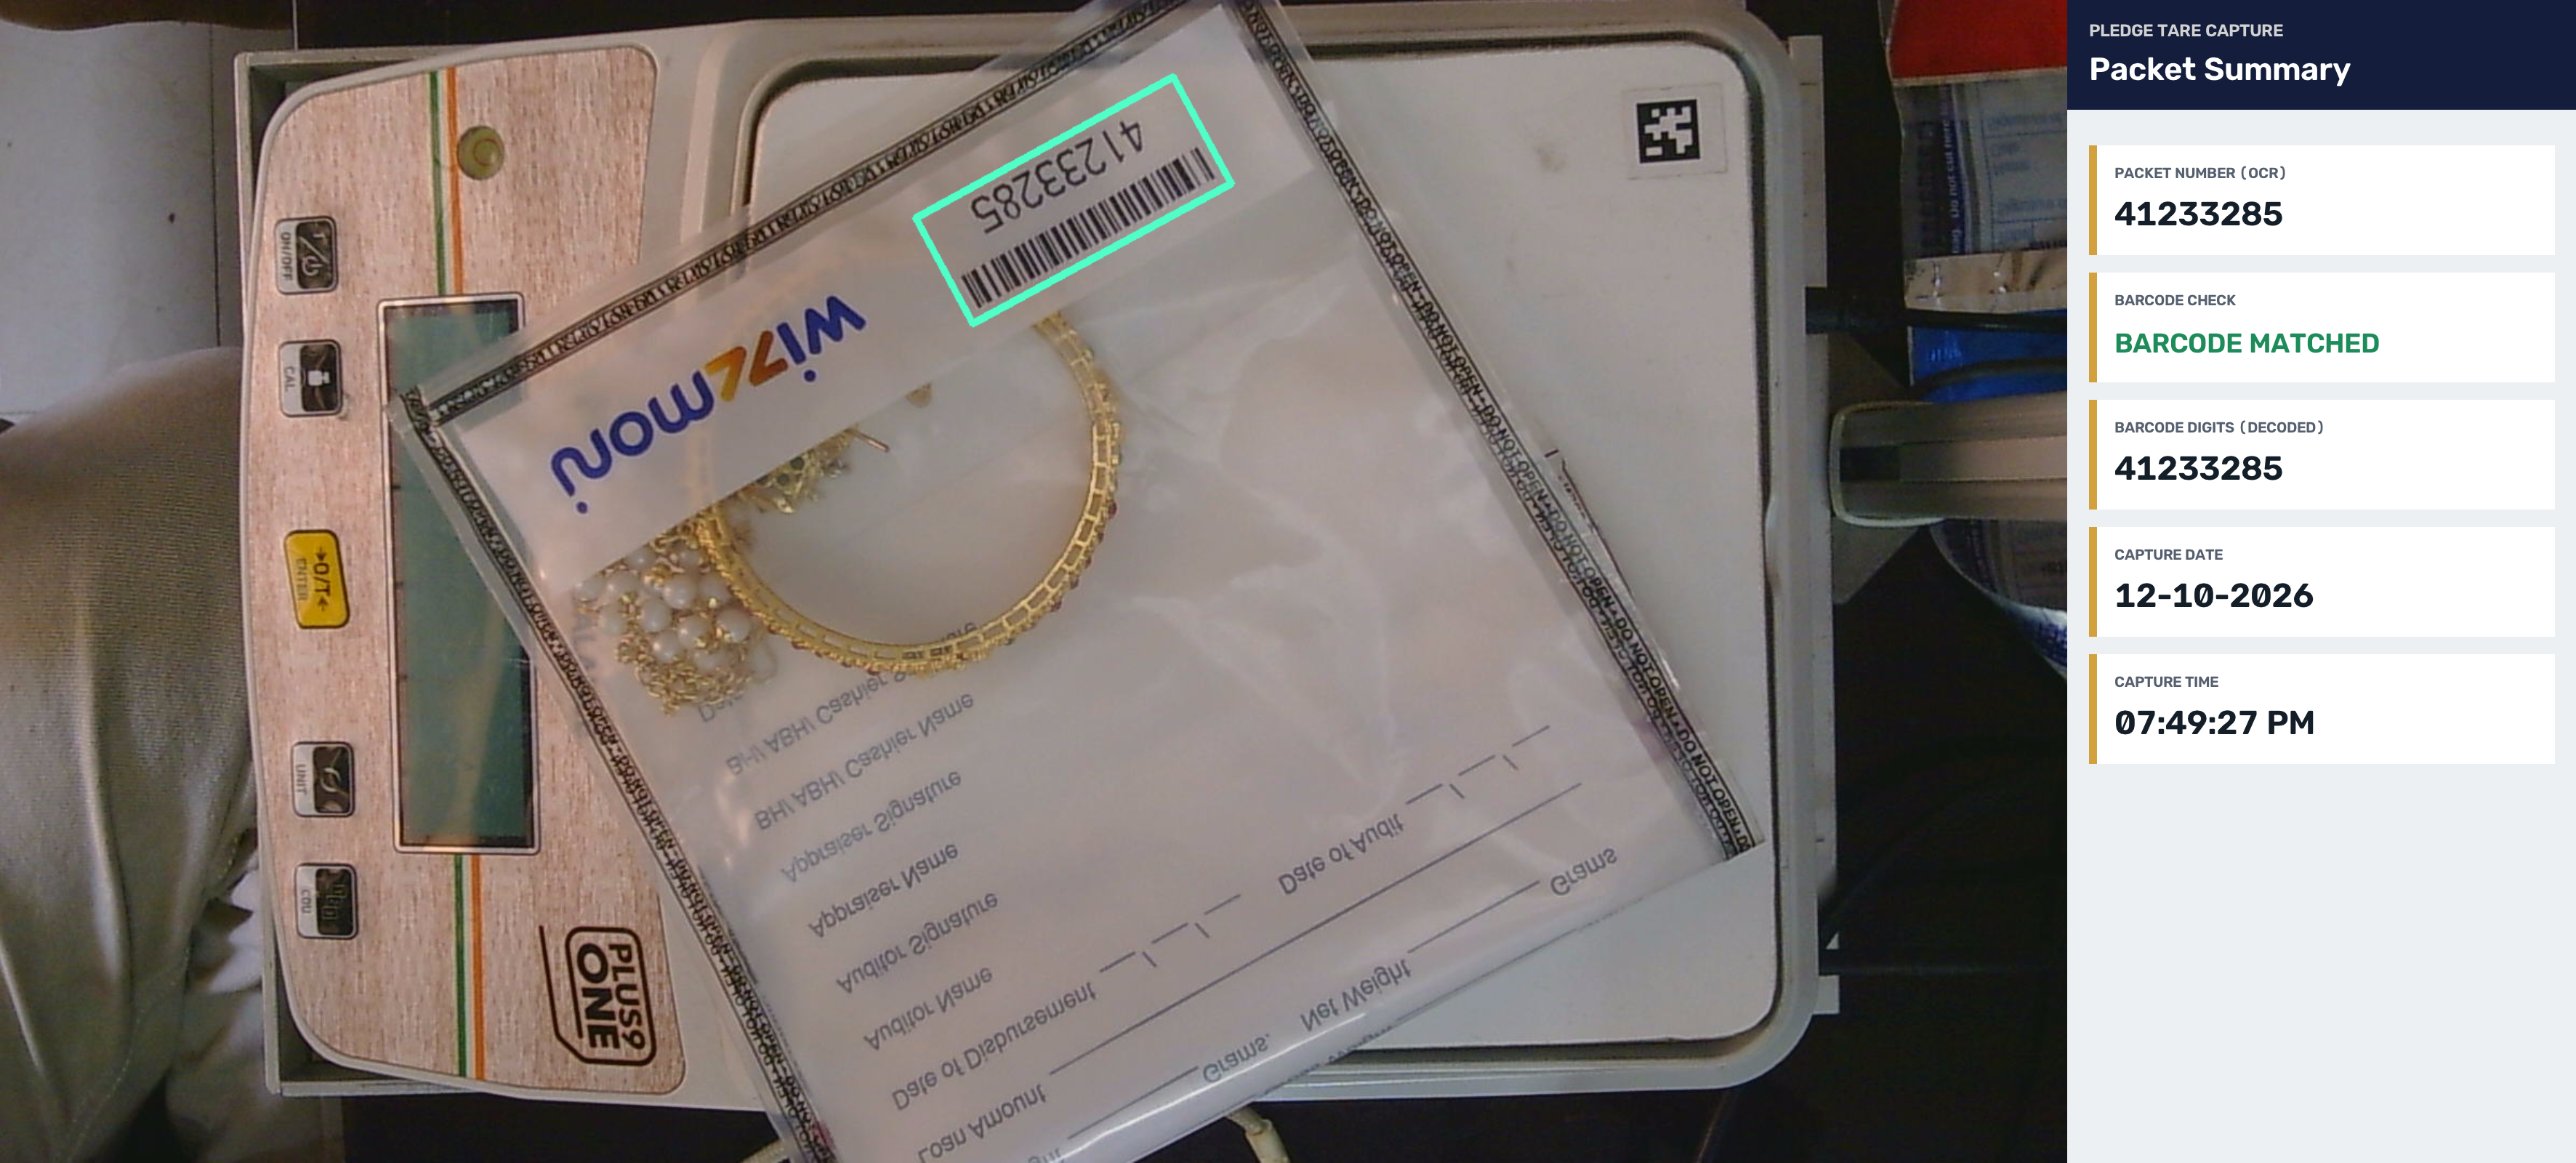

In [5]:
IMAGE_PATH = r"image5.png"          # <- change this
USE_YOLO   = False                      # True = try the Hugging Face YOLO model first (needs ultralytics + internet)

res  = B.process(IMAGE_PATH, use_yolo=USE_YOLO)
img  = cv2.imread(IMAGE_PATH)
B.annotate(img, res, "single_result.png")

status = ("BARCODE MATCHED" if res["match"] else "MISMATCH - CHECK") if (res["decoded"] and res["ocr"]) else \
         ("BARCODE DECODED, OCR NOT READ" if res["decoded"] else "NOT FOUND")
print("Decoded barcode :", res["decoded"], f"({res.get('type')})")
print("OCR number      :", res["ocr"])
print("Result          :", status)
info = res.get("ocr_info", {})
if info:
    print("OCR detail      :", info)   # templates = digit reader, tesseract = 2nd opinion, dist_max = how unsure (<=20 is fine)
display(IPImage("single_result.png", width=1100))

## Section B: run a whole folder

In [6]:
DATASET_DIR = r"barcode OCR test"       # <- change this (sub-folders are searched too)
OUT_DIR     = "output"

paths = B.collect(DATASET_DIR)
assert paths, f"No images found in {os.path.abspath(DATASET_DIR)}"
B.run_on(paths, OUT_DIR, use_yolo=USE_YOLO)
df = pd.read_csv(os.path.join(OUT_DIR, "results.csv"))
print(df["match"].value_counts(dropna=False))
df

{'file': 'Barcode_20260916_121447_260_png.rf.z5mJJqK97vtwPdeLr0tY.png', 'decoded': '41233285', 'type': 'CODE128', 'ocr': '41233285', 'match': True, 'detector': 'classical'}
{'file': 'Barcode_20260916_121931_940_png.rf.v6tbtKM6NqX2cfRYEBgT.png', 'decoded': '3535290', 'type': 'CODE128', 'ocr': '3535290', 'match': True, 'detector': 'classical'}
{'file': 'Barcode_20260916_122434_798_png.rf.q50hCIF43vqtuq3mdIus.png', 'decoded': None, 'type': None, 'ocr': None, 'match': None, 'detector': None}
{'file': 'Barcode_20260916_121207_954_png.rf.xnkn9FRL2wu2ok2Lx1FW.png', 'decoded': '41233285', 'type': 'CODE128', 'ocr': '41233285', 'match': True, 'detector': 'classical'}
{'file': 'Barcode_20260916_121215_325_png.rf.qnLbbAHVLMgJ5JlNYGWW.png', 'decoded': '41233285', 'type': 'CODE128', 'ocr': '41233285', 'match': True, 'detector': 'classical'}
{'file': 'Barcode_20260916_121219_742_png.rf.zzMSgGItT5pK9nwRzqTP.png', 'decoded': '41233285', 'type': 'CODE128', 'ocr': '41233285', 'match': True, 'detector': '

,file,decoded,type,ocr,match,detector
0,Barcode_20260916_121447_260_png.rf.z5mJJqK97vt...,41233285.0,CODE128,41233285.0,True,classical
1,Barcode_20260916_121931_940_png.rf.v6tbtKM6NqX...,3535290.0,CODE128,3535290.0,True,classical
2,Barcode_20260916_122434_798_png.rf.q50hCIF43vq...,NaN,NaN,NaN,NaN,NaN
3,Barcode_20260916_121207_954_png.rf.xnkn9FRL2wu...,41233285.0,CODE128,41233285.0,True,classical
4,Barcode_20260916_121215_325_png.rf.qnLbbAHVLMg...,41233285.0,CODE128,41233285.0,True,classical
5,Barcode_20260916_121219_742_png.rf.zzMSgGItT5p...,41233285.0,CODE128,41233285.0,True,classical
6,Barcode_20260916_121248_237_png.rf.v2zy1mHyoeB...,41233285.0,CODE128,41233285.0,True,classical
7,Barcode_20260916_121253_696_png.rf.pTMbA8W6FRf...,41233285.0,CODE128,41233285.0,True,classical
8,Barcode_20260916_121309_477_png.rf.cExa0MUGElA...,41233285.0,CODE128,41233285.0,True,classical
9,Barcode_20260916_121324_107_png.rf.ooKfYZAI04e...,41233285.0,CODE128,41233285.0,True,classical


## Section C: OCR only (no barcode needed) - for debugging a bad read
Give the packet photo and the rectangle of the bars `((cx, cy), (long_side, short_side), angle)`; prints every digit reading.

In [7]:
img  = cv2.imread(IMAGE_PATH)
rect = ((777, 145), (190, 70), -53.0)   # <- example for task_img2.jpeg ; the pipeline normally supplies this
txt, votes, info = B.ocr_number(img, rect, return_info=True)
print(txt, info)

None {'method': 'legacy'}


In [9]:
b = 500
try:
    li = eval(input("enter the number : "))
    a = input("Enter the number : ")
    print(a[i])

except BaseException as e:
    print(e)

print(b)

name 'dfghjkl' is not defined
500


In [11]:
chr(97)


'a'

In [12]:
x = [11,22,33]
y = [11,22,30]
x>=y

True

In [ ]:
class BankAccount:
    def __init__(self, balance):
        self.__balance = balance

    def deposit(self, amount):
        if amount > 0:
            self.__balance += amount
            print("Deposit successful")
        else:
            print("Invalid amount")

    def show_balance(self):
        print("Balance:", self.__balance)


account = BankAccount(1000)

account.deposit(500)
account.show_balance()

Deposit successful
Balance: 1500


In [4]:
class bankaccount:
    def __init__(self,balance):
        self.__balance = balance

    def deposit(self,amount):   
        if amount>0:
            self.__balance +=amount
            
        else :
            print("Inavlid")

    def Withdraw(self,amount):
        if self.__balance > amount:   
            self.__balance -= amount
        else:
            print("Invalid balance")    
                 
    def show(self):
        print("Balance :",self.__balance) 

account = bankaccount(1000)
account.deposit(500)
account.Withdraw(500)
account.show()



Balance : 1000


In [30]:
class Employee:
    def __init__(self, salary):
        self.__salary = salary


    def increase_salary(self, amount):
        # Check whether amount is positive
        if amount > 0 :
            self.__salary += amount


        


    def show_salary(self):
        print(self.__salary)

obj = Employee(10000) 
obj.increase_salary(100) 
obj.show_salary()      

10100


In [ ]:
It is possible show the error based on user requirement by using "raise" keyword

It is manitory to known about the name of the exception 




In [ ]:
st = "Captain"
n = input("Enter the value")
if n not in st:
    raise ValueError("Value is not present")

In [ ]:
# User define exception

# it is a process of creating the exception based on user requirement  in this user define exception it is possible to create a new exception with the speard name  

# in this user defined exception it is manitory to create the expression by using one class and to exception is manitory to use raise keyword also 


# assert

# it is a keyword which will help user to create a  error based on the condition

# if the condition is true then true statement block will get excuted else controll will thrown 




In [3]:

class BankAccount:
    def __init__(self, balance):
        self.__balance = balance

    def deposit(self, amount):
        if amount > 0:
            self.__balance += amount
            print("Deposit successful")
        else:
            print("Invalid deposit amount")

    def withdraw(self, amount):
        if amount > 0 and self.__balance >= amount:
            self.__balance -= amount
            print("Withdrawal successful")
        else:
            print("Invalid withdrawal amount or balance")

    def show(self):
        print("Balance:", self.__balance)


account = BankAccount(1000)

account.deposit(500)
account.withdraw(500)
account.show()


Deposit successful
Withdrawal successful
Balance: 1000
